# AP 155 Lab Exercise
---
## Exercise 7: Root Finding

_Instructions_:
- **Report figure:** (See Problem) Plot the convergence of the values towards the root of $f(x)$. That is, plot $x_i$ vs. $i$ for each of the four methods ($x_i$ is the output of the method on the $i$th step). Overlay the convergence curves on a single plot and check the convergence. You may have more than four curves; for instance, you could have used newton's method twice for two different guesses. Make sure to label your curves (method + initial guesses).
- **Report discussion:**
    - Explain the report figure.
    - What are the advantages and disadvantages of the root-finding methods?
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name_: Buhangin, Ahrystan Deniz
- _Student No._: 2024-07766
- _Section_: THR-TX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view?usp=sharing) (Note: percentages may still be tweaked)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | <span style="color:red"> 12 </span> | 20 |
| Report discussion | <span style="color:red"> 16 </span> | 20|
| Code readability | <span style="color:red"> 20 </span> | 20 |
| Code efficiency | <span style="color:red"> 20 </span> | 20 |
| Code appropriateness  | <span style="color:red"> 18 </span> | 20 |
| **TOTAL** | <span style="color:red"> 86 </span> | 100 |

<span style="color:red"> *Comments: Need to find the other roots. In report discussion, did not seem to answer the advantages/disadvantages question* </span>

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM) <span style="color:red"> 10/14/2026 </span>

---
## Section 1: Report

### Report figure

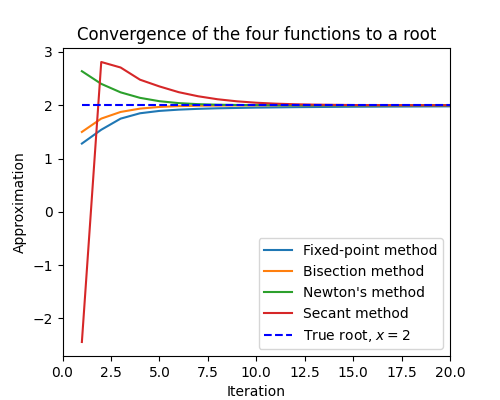


### Report discussion

Usually, the convergence of both fixed point and bisection method are the slowest as they are linear. This is followed by the secant method which is superlinear, and the Newton's method which converges at a quadratic pace. For the particular case in the graph, however, we can see that the convergence rate for fixed-point, bisection, and Newton's method were roughly the same, while the convergence rate of the secant method was the slowest.

### Other comments
- EDIT ME
- A self reflection can be placed here.
- This portion is not graded.
- You may insert further questions here.


---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math

### Problem 1: Root Finding


Implement root finders *manually* to find the roots of an arbitrary function

1. fixed-point method (relaxation, needs an initial guess)
2. bisection method (bracketing, needs two bounds)
3. newton's method (known derivative, needs an initial guess)
4. secant method (approximate derivative, needs two initial guesses)

Consider the function

$$
f(x) = -x^5 + 4x^4 - 4x^3 + x^2 e^x - 2x^2 -4xe^x + 8x + 4e^x -8
$$

5. Plot the function from x=-2 to x=-5. You may want to "enlarge" the plot by rescaling/"cropping" the y-axis. You should be able to estimate where the roots are approximately
   
6. Find the roots of $f(x)$ by implementing the four methods shown.

7. Report Figure: Plot the convergence of the values towards the root of $f(x)$. That is, plot $x_i$ vs. $i$ for each of the four methods ($x_i$ is the output of the method on the $i$th step). Overlay the convergence curves on a single plot and check the convergence. You may have more than four curves; for instance, you could have used newton's method twice for two different guesses. Make sure to label your curves (method + initial guesses).

1.9972593307059885


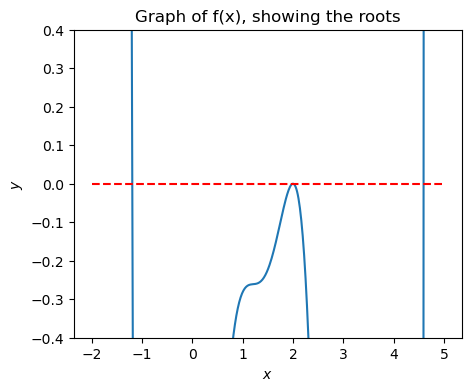

In [2]:
# Fixed-point method
tol = 1e-5

def f(x):
  return -(x**5) + 4*(x**4) - 4*(x**3) + (x**2)*(np.exp(x)) - 2*(x**2) - 4*x*(np.exp(x)) + 8*x + 4*(np.exp(x)) - 8

def g(x):
  return x - f(x)

def fixed_point(x_old, g, tol, kmax = 200):
  Fixed_new = []
  for k in range(1, kmax):
    x_new = g(x_old)
    x_diff = x_new - x_old
    Fixed_new.append(x_new)

    if abs(x_diff/x_new) < tol:
      for i in range(k, kmax):
        Fixed_new.append(x_new)
      break

    x_old = x_new
  else:
    x_new = None

  return x_new, np.array(Fixed_new)

fixed_root, fixed_steps = fixed_point(1, g, tol)
print(fixed_root)

X = np.linspace(-2, 5, 500)
plt.figure(figsize=(5, 4))
plt.plot(X, f(X))
plt.plot(X, f(X) - f(X), 'r--')
plt.xlabel("$x$")
plt.ylabel("$y$")
plt.ylim(-0.4, 0.4)
plt.title("Graph of f(x), showing the roots")
plt.show()

In [3]:
# Bisection method

def bisection(f, a, b, tol, kmax=200):
  Midpoint_new = []
  f_a = f(a)
  for k in range(1, kmax):
    midpoint = (a + b) / 2
    f_mid = f(midpoint)

    if f_mid * f_a < 0:
      b = midpoint
    elif f_mid == 0:
      return midpoint
    else:
      a, f_a = midpoint, f_mid

    midpoint_new = (a + b) / 2
    Midpoint_new.append(midpoint)
    diff = abs(midpoint_new - midpoint)

    if abs(diff/midpoint_new) < tol:
      for i in range(k, kmax):
        Midpoint_new.append(midpoint_new)
      break
  else:
    midpoint_new = None
  return midpoint_new, np.array(Midpoint_new)

print('Roots at x =', bisection(f, -2, -1, tol)[0], ",", bisection(f, 1, 2, tol)[0], ",", bisection(f, 4, 5, tol)[0])




Roots at x = -1.1926803588867188 , 1.9999847412109375 , 4.595855712890625


In [4]:
# Newton's method

def f_p(x):
  return -5*(x**4) + 16*(x**3) - 12*(x**2) + (x**2)*(np.exp(x)) + 2*x*(np.exp(x)) - 4*x -4*x*(np.exp(x)) - 4*(np.exp(x)) + 8 + 4*(np.exp(x))

def newton(f, fp, x_0, tol, kmax=200):
  Newton_new = []
  for k in range(1, kmax):
    f_0, fp_0 = f(x_0), fp(x_0)
    x_new = x_0 - (f_0 / fp_0)
    diff = abs(x_0 - x_new)
    Newton_new.append(x_new)

    if abs(diff/x_new) < tol:
      for i in range(k, kmax):
        Newton_new.append(x_new)
      break

    x_0 = x_new
  else:
    x_new = None
  return x_new, np.array(Newton_new)

print(newton(f, f_p, 1.5, tol)[0])

2.0000150043412903


In [5]:
# Secant method

def secant(f, x_0, x_1, tol, kmax=200):
  f_0 = f(x_0)
  Secant_new = []
  for k in range(1, kmax):
    f_1 = f(x_1)
    ratio = (x_1 - x_0) / (f_1 - f_0)
    x_new = x_1 - f_1*ratio
    Secant_new.append(x_new)

    diff = abs(x_new - x_1)
    x_0, x_1 = x_1, x_new
    f_0 = f_1

    if abs(diff/x_new) < tol:
      for i in range(k, kmax):
        Secant_new.append(x_new)
      break
  else:
    x_new = None
  return x_new, np.array(Secant_new)

print(secant(f, 0, 3, tol)[0])

2.000023604343922


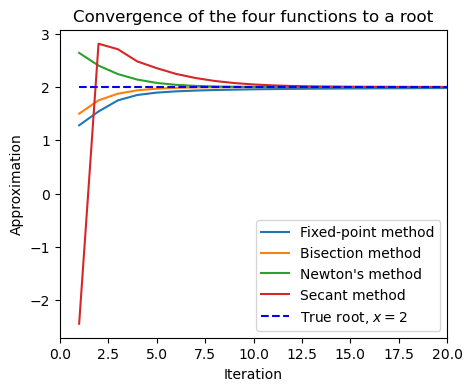

In [6]:
kmax = 200
X = np.linspace(1, kmax, kmax)

plt.figure(figsize=(5, 4))
plt.plot(X, fixed_point(1, g, tol)[1], label="Fixed-point method")
plt.plot(X, bisection(f, 1, 2, tol)[1], label="Bisection method")
plt.plot(X, newton(f, f_p, 3, tol)[1], label="Newton's method")
plt.plot(X, secant(f, 0, 3, tol)[1], label="Secant method")
plt.plot(X, X - X + 2, 'b--', label="True root, $x = 2$")
plt.xlim(0, 20)
plt.xlabel("Iteration")
plt.ylabel("Approximation")
plt.title("Convergence of the four functions to a root")
plt.legend()
plt.savefig("convergence.png")
plt.show()



#### Problem 1 code summary

The above code simply implements the iterative convergence given the four methods of fixed-point, bisection, Newton's, and secant. The convergence rate of these four alogrithms in obtaining the common root of $x = 2$ was also graphed.

---